# Юнит-экономика и окупаемость маркетинга приложения

**Цель:** оценить активность аудитории и эффективность рекламных каналов развлекательного приложения: от привлечения пользователя до выручки и окупаемости маркетинговых затрат.

**Ключевые метрики:** DAU, MAU, Stickiness, rolling retention, conversion, CAC, LTV, ROI, ARPPU и payback.

**Стек:** Python, pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook.

**Период данных:** 1 апреля — 30 ноября 2024 года.

> Исходные данные загружаются из внешнего учебного источника и не дублируются в репозитории.

## 1. Загрузка и проверка данных

Используются три таблицы:

- сессии пользователей;
- покупки;
- ежедневные маркетинговые расходы по каналам.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")

HORIZON_DAYS = 28
RETENTION_START_DAY = 14
RETENTION_END_DAY = 28

CHANNEL_COLORS = {
    "FaceBoom": "#E45756",
    "MediaTornado": "#72B7B2",
    "RocketSuperAds": "#4C78A8",
    "TipTop": "#F58518",
}

In [2]:
VISITS_URL = "https://code.s3.yandex.net/datasets/ppro_visits.csv"
ORDERS_URL = "https://code.s3.yandex.net/datasets/ppro_orders.csv"
COSTS_URL = "https://code.s3.yandex.net/datasets/ppro_costs.csv"

visits = pd.read_csv(VISITS_URL)
orders = pd.read_csv(ORDERS_URL)
costs = pd.read_csv(COSTS_URL)

dataset_summary = pd.DataFrame(
    {
        "Таблица": ["Сессии", "Покупки", "Маркетинговые расходы"],
        "Строки": [len(visits), len(orders), len(costs)],
        "Столбцы": [visits.shape[1], orders.shape[1], costs.shape[1]],
        "Полные дубликаты": [
            visits.duplicated().sum(),
            orders.duplicated().sum(),
            costs.duplicated().sum(),
        ],
        "Пропуски": [
            visits.isna().sum().sum(),
            orders.isna().sum().sum(),
            costs.isna().sum().sum(),
        ],
    }
)
display(dataset_summary)

,Таблица,Строки,Столбцы,Полные дубликаты,Пропуски
0,Сессии,161865,6,0,0
1,Покупки,33893,3,0,0
2,Маркетинговые расходы,976,3,0,0


In [3]:
visits["session_start"] = pd.to_datetime(
    visits["session_start"], format="%Y-%m-%d %H:%M:%S", errors="coerce"
)
visits["session_end"] = pd.to_datetime(
    visits["session_end"], format="%Y-%m-%d %H:%M:%S", errors="coerce"
)
orders["event_dt"] = pd.to_datetime(
    orders["event_dt"], format="%Y-%m-%d %H:%M:%S", errors="coerce"
)
costs["dt"] = pd.to_datetime(
    costs["dt"], format="%Y-%m-%d", errors="coerce"
)

orders["revenue"] = pd.to_numeric(orders["revenue"], errors="coerce")
costs["costs"] = pd.to_numeric(costs["costs"], errors="coerce")

quality_checks = pd.Series(
    {
        "Некорректные даты сессий": visits[
            ["session_start", "session_end"]
        ].isna().sum().sum(),
        "Некорректные даты покупок": orders["event_dt"].isna().sum(),
        "Некорректные даты расходов": costs["dt"].isna().sum(),
        "Сессии с окончанием раньше начала": (
            visits["session_end"] < visits["session_start"]
        ).sum(),
        "Отрицательная выручка": orders["revenue"].lt(0).sum(),
        "Отрицательные расходы": costs["costs"].lt(0).sum(),
        "Повторы даты и канала в расходах": costs.duplicated(
            subset=["dt", "channel"]
        ).sum(),
    },
    name="Количество",
)
display(quality_checks.to_frame())

print(
    "Период сессий:",
    visits["session_start"].min(),
    "—",
    visits["session_start"].max(),
)

Период сессий: 2024-04-01 00:07:00 — 2024-11-30 23:59:00


,Количество
Некорректные даты сессий,0
Некорректные даты покупок,0
Некорректные даты расходов,0
Сессии с окончанием раньше начала,0
Отрицательная выручка,0
Отрицательные расходы,0
Повторы даты и канала в расходах,0


**Промежуточный вывод.** В данных 161 865 сессий, 33 893 покупки и 976 записей о маркетинговых расходах. Пропусков, полных дубликатов, отрицательных значений и нарушений хронологии не обнаружено. Таблицы покрывают один и тот же период.

## 2. Профили пользователей и стоимость привлечения

Первой сессией определим дату, устройство, регион и канал привлечения пользователя. CAC рассчитывается для каждой комбинации даты и канала как расходы, делённые на число новых пользователей.

In [4]:
profiles = (
    visits.sort_values(["user_id", "session_start"])
    .drop_duplicates(subset="user_id")
    [["user_id", "session_start", "channel", "device", "region"]]
    .rename(
        columns={
            "session_start": "first_session_start",
            "channel": "first_channel",
            "device": "first_device",
            "region": "first_region",
        }
    )
    .copy()
)
profiles["first_dt"] = profiles["first_session_start"].dt.normalize()
profiles["cohort_month"] = (
    profiles["first_dt"].dt.to_period("M").dt.to_timestamp()
)
profiles["cohort_week"] = (
    profiles["first_dt"].dt.to_period("W-SUN").dt.start_time
)

daily_users = (
    profiles.groupby(["first_dt", "first_channel"], as_index=False)
    .agg(new_users=("user_id", "nunique"))
)

daily_costs = costs.rename(
    columns={"dt": "first_dt", "channel": "first_channel"}
)
daily_acquisition = daily_users.merge(
    daily_costs,
    on=["first_dt", "first_channel"],
    how="left",
    validate="one_to_one",
)
daily_acquisition["cac"] = (
    daily_acquisition["costs"] / daily_acquisition["new_users"]
)

profiles = profiles.merge(
    daily_acquisition[["first_dt", "first_channel", "cac"]],
    on=["first_dt", "first_channel"],
    how="left",
    validate="many_to_one",
)

print(f"Профилей пользователей: {len(profiles):,}")
print(
    "Групп привлечения без расходов:",
    daily_acquisition["costs"].isna().sum(),
)

Профилей пользователей: 74,856
Групп привлечения без расходов: 0


In [5]:
costs_without_users = daily_costs.merge(
    daily_users[["first_dt", "first_channel"]],
    on=["first_dt", "first_channel"],
    how="left",
    indicator=True,
    validate="one_to_one",
)

assigned_costs = profiles["cac"].sum()
actual_costs = costs["costs"].sum()

print(
    "Строк расходов без новых пользователей:",
    costs_without_users["_merge"].eq("left_only").sum(),
)
print(f"Расходы в таблице: {actual_costs:,.2f}")
print(f"Расходы, распределённые по пользователям: {assigned_costs:,.2f}")
print(f"Расхождение: {abs(actual_costs - assigned_costs):.10f}")

Строк расходов без новых пользователей: 0
Расходы в таблице: 79,731.30
Расходы, распределённые по пользователям: 79,731.30
Расхождение: 0.0000000000


In [6]:
profile_columns = profiles[
    ["user_id", "first_dt", "first_channel", "cac", "cohort_week"]
]

visits_cohort = visits.merge(
    profile_columns,
    on="user_id",
    how="left",
    validate="many_to_one",
)
orders_cohort = orders.merge(
    profile_columns,
    on="user_id",
    how="left",
    validate="many_to_one",
)

visits_cohort["lifetime"] = (
    visits_cohort["session_start"].dt.normalize()
    - visits_cohort["first_dt"]
).dt.days
orders_cohort["lifetime"] = (
    orders_cohort["event_dt"].dt.normalize()
    - orders_cohort["first_dt"]
).dt.days

print("Покупок без профиля:", orders_cohort["first_dt"].isna().sum())
print("Покупок до привлечения:", orders_cohort["lifetime"].lt(0).sum())

Покупок без профиля: 0
Покупок до привлечения: 0


**Промежуточный вывод.** Сформировано 74 856 пользовательских профилей. Все маркетинговые расходы распределены между привлечёнными пользователями без потерь, а покупки корректно связаны с профилями и лайфтаймом.

## 3. Портрет аудитории

Регион в выборке один — India, поэтому региональная сегментация невозможна. Рассмотрим устройства и каналы первой сессии.

,device,users,share_pct
0,mobile,44446,59.40
1,desktop,25983,34.70
2,tv,4427,5.90


,first_channel,users,share_pct
0,FaceBoom,28401,37.90
3,TipTop,18118,24.20
2,RocketSuperAds,14257,19.00
1,MediaTornado,14080,18.80


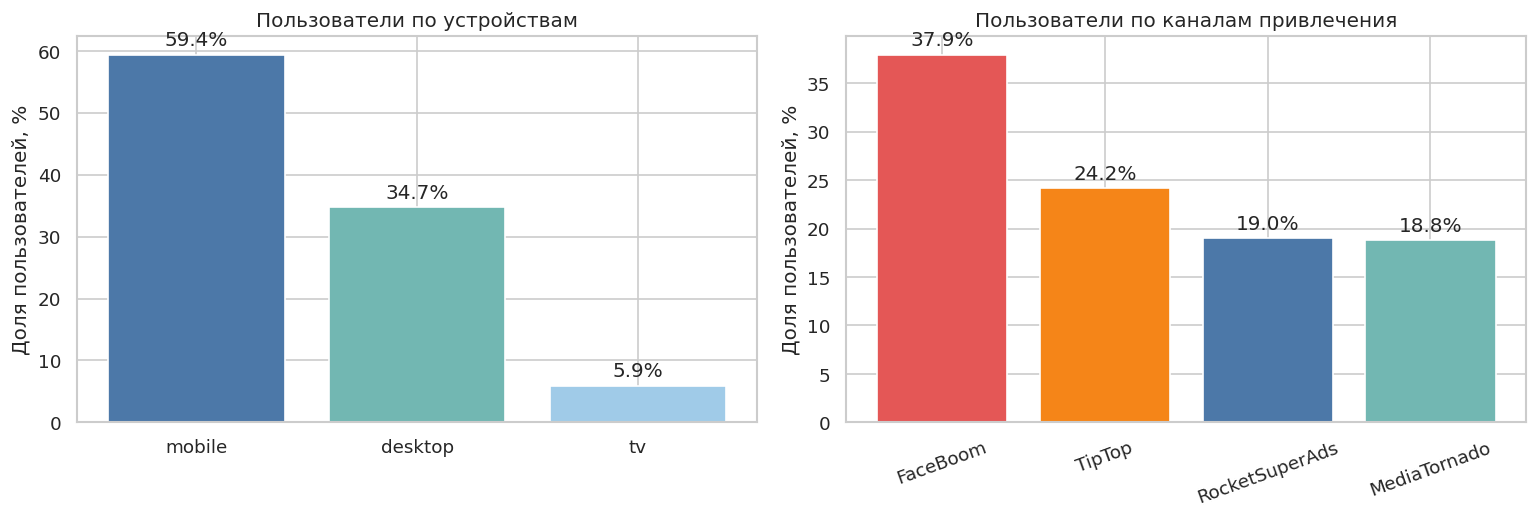

In [7]:
device_summary = (
    profiles["first_device"]
    .value_counts()
    .rename_axis("device")
    .reset_index(name="users")
)
device_summary["share_pct"] = (
    device_summary["users"] / device_summary["users"].sum() * 100
)

channel_users = (
    profiles.groupby("first_channel", as_index=False)
    .agg(users=("user_id", "nunique"))
    .sort_values("users", ascending=False)
)
channel_users["share_pct"] = (
    channel_users["users"] / channel_users["users"].sum() * 100
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

device_bars = axes[0].bar(
    device_summary["device"],
    device_summary["share_pct"],
    color=["#4C78A8", "#72B7B2", "#A0CBE8"],
)
axes[0].set_title("Пользователи по устройствам")
axes[0].set_xlabel("")
axes[0].set_ylabel("Доля пользователей, %")
axes[0].bar_label(device_bars, fmt="%.1f%%", padding=3)

channel_bars = axes[1].bar(
    channel_users["first_channel"],
    channel_users["share_pct"],
    color=[CHANNEL_COLORS[channel] for channel in channel_users["first_channel"]],
)
axes[1].set_title("Пользователи по каналам привлечения")
axes[1].set_xlabel("")
axes[1].set_ylabel("Доля пользователей, %")
axes[1].tick_params(axis="x", rotation=20)
axes[1].bar_label(channel_bars, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

display(device_summary.round(1))
display(channel_users.round(1))

**Вывод.** 59,4% пользователей впервые открыли приложение с мобильного устройства, 34,7% — с desktop, 5,9% — с TV. Крупнейший канал — FaceBoom: он привёл 28 401 пользователя, или около 38% аудитории.

## 4. Динамика активности продукта

DAU рассчитывается по каждому календарному дню, включая дни без сессий. MAU — число уникальных активных пользователей в месяце. Stickiness определяется как средний DAU, делённый на MAU.

In [8]:
activity = visits_cohort.copy()
activity["activity_dt"] = activity["session_start"].dt.normalize()
activity["activity_month"] = (
    activity["session_start"].dt.to_period("M").dt.to_timestamp()
)

calendar = pd.date_range(
    activity["activity_dt"].min(), activity["activity_dt"].max(), freq="D"
)
daily_activity = (
    activity.groupby("activity_dt")["user_id"]
    .nunique()
    .reindex(calendar, fill_value=0)
    .rename_axis("activity_dt")
    .reset_index(name="dau")
)
daily_activity["activity_month"] = (
    daily_activity["activity_dt"].dt.to_period("M").dt.to_timestamp()
)

monthly_mau = (
    activity.groupby("activity_month", as_index=False)
    .agg(mau=("user_id", "nunique"))
)
monthly_activity = (
    daily_activity.groupby("activity_month", as_index=False)
    .agg(avg_dau=("dau", "mean"))
    .merge(monthly_mau, on="activity_month", validate="one_to_one")
)
monthly_activity["stickiness_pct"] = (
    monthly_activity["avg_dau"] / monthly_activity["mau"] * 100
)

display(monthly_activity.round(2))

,activity_month,avg_dau,mau,stickiness_pct
0,2024-04-01,488.33,9069,5.38
1,2024-05-01,576.97,10849,5.32
2,2024-06-01,580.37,10240,5.67
3,2024-07-01,615.00,10864,5.66
4,2024-08-01,681.19,11977,5.69
5,2024-09-01,724.10,12089,5.99
6,2024-10-01,773.19,13036,5.93
7,2024-11-01,868.13,14097,6.16


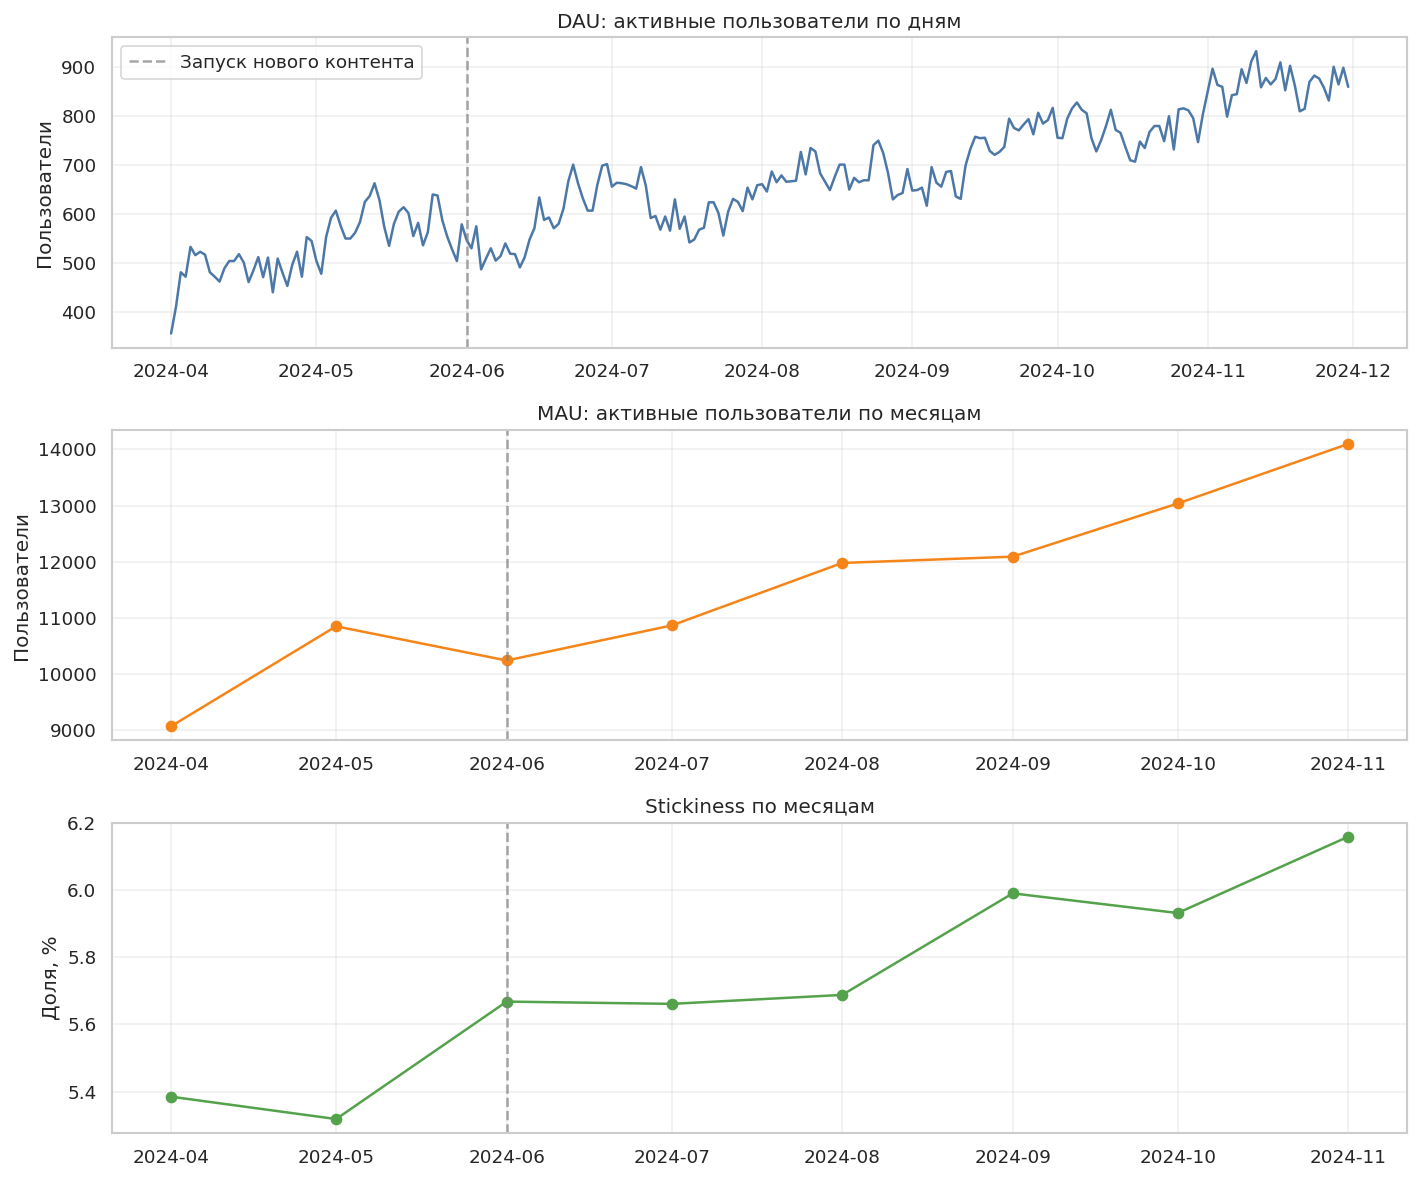

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10))

axes[0].plot(
    daily_activity["activity_dt"], daily_activity["dau"], color="#4C78A8"
)
axes[0].set_title("DAU: активные пользователи по дням")
axes[0].set_ylabel("Пользователи")

axes[1].plot(
    monthly_activity["activity_month"],
    monthly_activity["mau"],
    marker="o",
    color="#F58518",
)
axes[1].set_title("MAU: активные пользователи по месяцам")
axes[1].set_ylabel("Пользователи")

axes[2].plot(
    monthly_activity["activity_month"],
    monthly_activity["stickiness_pct"],
    marker="o",
    color="#54A24B",
)
axes[2].set_title("Stickiness по месяцам")
axes[2].set_ylabel("Доля, %")

for ax in axes:
    ax.axvline(
        pd.Timestamp("2024-06-01"),
        color="gray",
        linestyle="--",
        alpha=0.7,
        label="Запуск нового контента",
    )
    ax.grid(alpha=0.3)

axes[0].legend()
plt.tight_layout()
plt.show()

**Вывод.** С апреля по ноябрь средний DAU вырос с 488 до 868, MAU — с 9 069 до 14 097, Stickiness — с 5,38% до 6,16%. В июне MAU временно снизился, поэтому рост Stickiness в этом месяце сам по себе не доказывает эффект нового контента. Устойчивая положительная динамика проявилась позднее.

## 5. Месячная динамика CAC, LTV и ROI

LTV и ROI считаются на горизонте первых 28 дней после привлечения. Метрики показываются только для месяцев, в которых все пользователи успели прожить полный горизонт наблюдения.

In [10]:
monthly_users = (
    profiles.groupby("cohort_month", as_index=False)
    .agg(users=("user_id", "nunique"))
)
monthly_costs = (
    costs.assign(
        cohort_month=costs["dt"].dt.to_period("M").dt.to_timestamp()
    )
    .groupby("cohort_month", as_index=False)
    .agg(marketing_costs=("costs", "sum"))
)

orders_28 = orders_cohort.loc[
    orders_cohort["lifetime"].between(0, HORIZON_DAYS - 1)
].copy()
orders_28["cohort_month"] = (
    orders_28["first_dt"].dt.to_period("M").dt.to_timestamp()
)
monthly_revenue = (
    orders_28.groupby("cohort_month", as_index=False)
    .agg(revenue_28d=("revenue", "sum"))
)

monthly_financial = (
    monthly_users.merge(monthly_costs, on="cohort_month", validate="one_to_one")
    .merge(monthly_revenue, on="cohort_month", how="left", validate="one_to_one")
    .fillna({"revenue_28d": 0})
)
monthly_financial["cac"] = (
    monthly_financial["marketing_costs"] / monthly_financial["users"]
)

data_end = min(
    visits["session_start"].max().normalize(),
    orders["event_dt"].max().normalize(),
    costs["dt"].max().normalize(),
)
last_complete_acquisition_dt = data_end - pd.Timedelta(
    days=HORIZON_DAYS - 1
)
monthly_financial["complete_28d"] = (
    monthly_financial["cohort_month"] + pd.offsets.MonthEnd(0)
    <= last_complete_acquisition_dt
)
monthly_financial["ltv_28d"] = (
    monthly_financial["revenue_28d"] / monthly_financial["users"]
).where(monthly_financial["complete_28d"])
monthly_financial["roi_28d_pct"] = (
    (monthly_financial["ltv_28d"] - monthly_financial["cac"])
    / monthly_financial["cac"].where(monthly_financial["cac"].ne(0))
    * 100
)

display(monthly_financial.round(3))

,cohort_month,users,marketing_costs,revenue_28d,cac,complete_28d,ltv_28d,roi_28d_pct
0,2024-04-01,9069,6663.05,7425.63,0.73,True,0.82,11.45
1,2024-05-01,9789,7327.77,8141.76,0.75,True,0.83,11.11
2,2024-06-01,8719,8492.12,7447.84,0.97,True,0.85,-12.30
3,2024-07-01,8742,9217.08,9991.41,1.05,True,1.14,8.40
4,2024-08-01,9518,10999.01,10367.05,1.16,True,1.09,-5.75
5,2024-09-01,9198,10838.01,10085.88,1.18,True,1.10,-6.94
6,2024-10-01,9520,12595.40,11449.71,1.32,True,1.20,-9.10
7,2024-11-01,10301,13598.85,8893.98,1.32,False,NaN,NaN


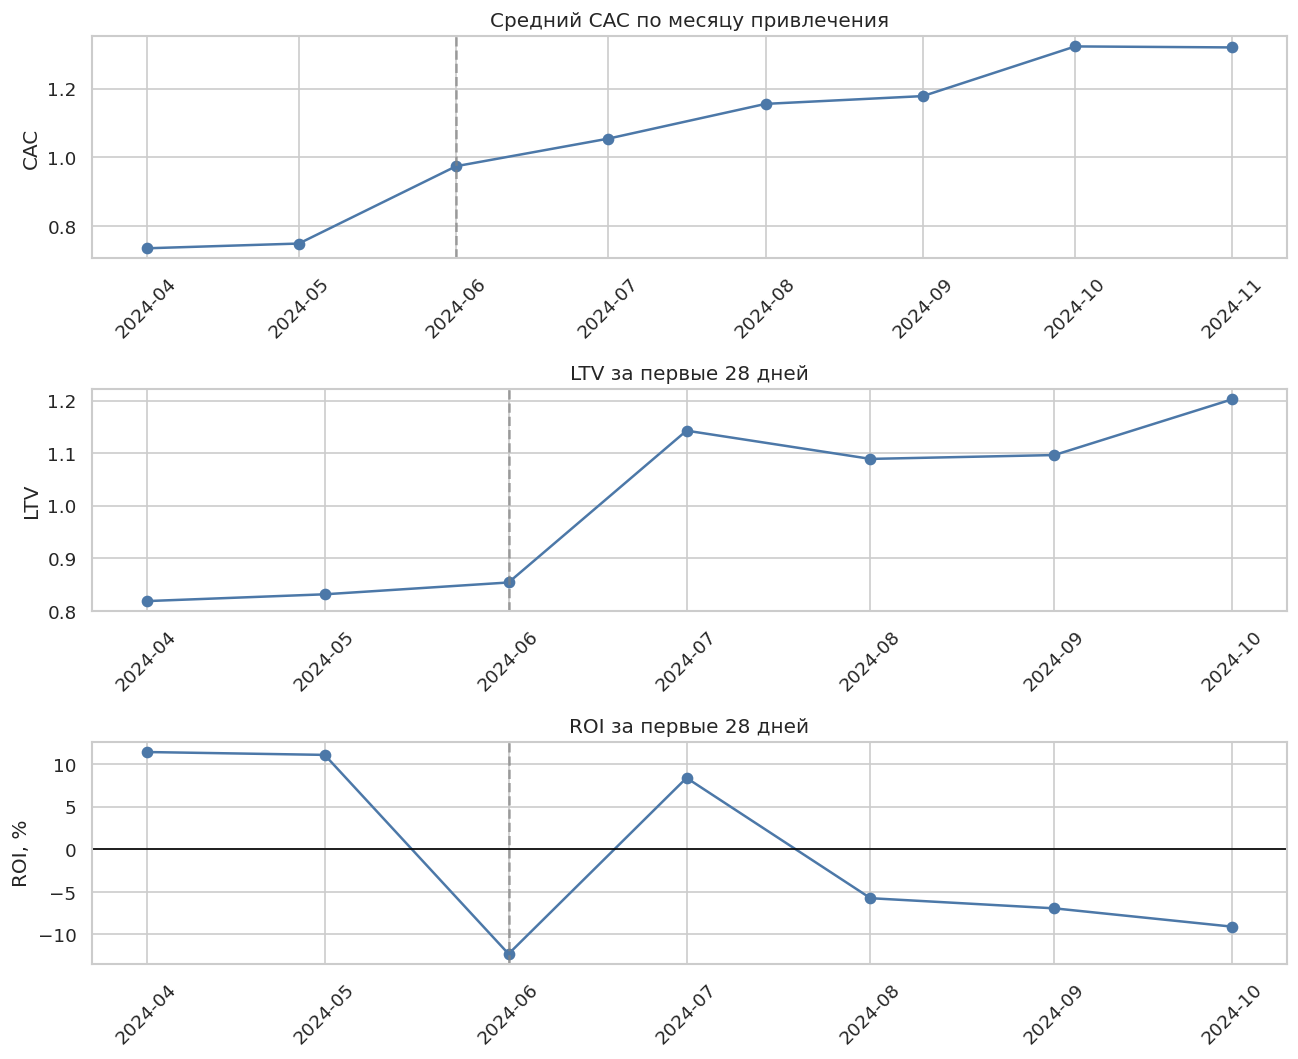

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9))
metrics = [
    ("cac", "Средний CAC по месяцу привлечения", "CAC"),
    ("ltv_28d", "LTV за первые 28 дней", "LTV"),
    ("roi_28d_pct", "ROI за первые 28 дней", "ROI, %"),
]

for ax, (column, title, ylabel) in zip(axes, metrics):
    ax.plot(
        monthly_financial["cohort_month"],
        monthly_financial[column],
        marker="o",
        color="#4C78A8",
    )
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=45)
    ax.axvline(
        pd.Timestamp("2024-06-01"),
        color="gray",
        linestyle="--",
        alpha=0.7,
    )

axes[2].axhline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

**Вывод.** С апреля по октябрь CAC вырос с 0,735 до 1,323 — примерно на 80%, тогда как 28-дневный LTV увеличился с 0,819 до 1,203 — примерно на 47%. ROI снизился с +11,4% до −9,1%. Ноябрь исключён из сравнения, поскольку полный 28-дневный горизонт для него не наблюдается.

## 6. Активность в разрезе каналов

Вся последующая активность пользователя относится к его первому каналу привлечения.

In [12]:
channel_daily_users = daily_users.pivot(
    index="first_dt", columns="first_channel", values="new_users"
).fillna(0)

activity_by_channel = visits_cohort.copy()
activity_by_channel["activity_dt"] = (
    activity_by_channel["session_start"].dt.normalize()
)
activity_by_channel["activity_month"] = (
    activity_by_channel["session_start"].dt.to_period("M").dt.to_timestamp()
)

channels = sorted(profiles["first_channel"].unique())
full_index = pd.MultiIndex.from_product(
    [calendar, channels], names=["activity_dt", "first_channel"]
)
channel_dau = (
    activity_by_channel.groupby(["activity_dt", "first_channel"])["user_id"]
    .nunique()
    .reindex(full_index, fill_value=0)
    .reset_index(name="dau")
)
channel_dau["activity_month"] = (
    channel_dau["activity_dt"].dt.to_period("M").dt.to_timestamp()
)
channel_mau = (
    activity_by_channel.groupby(
        ["activity_month", "first_channel"], as_index=False
    )
    .agg(mau=("user_id", "nunique"))
)
channel_activity = (
    channel_dau.groupby(
        ["activity_month", "first_channel"], as_index=False
    )
    .agg(avg_dau=("dau", "mean"))
    .merge(
        channel_mau,
        on=["activity_month", "first_channel"],
        validate="one_to_one",
    )
)
channel_activity["stickiness_pct"] = (
    channel_activity["avg_dau"] / channel_activity["mau"] * 100
)

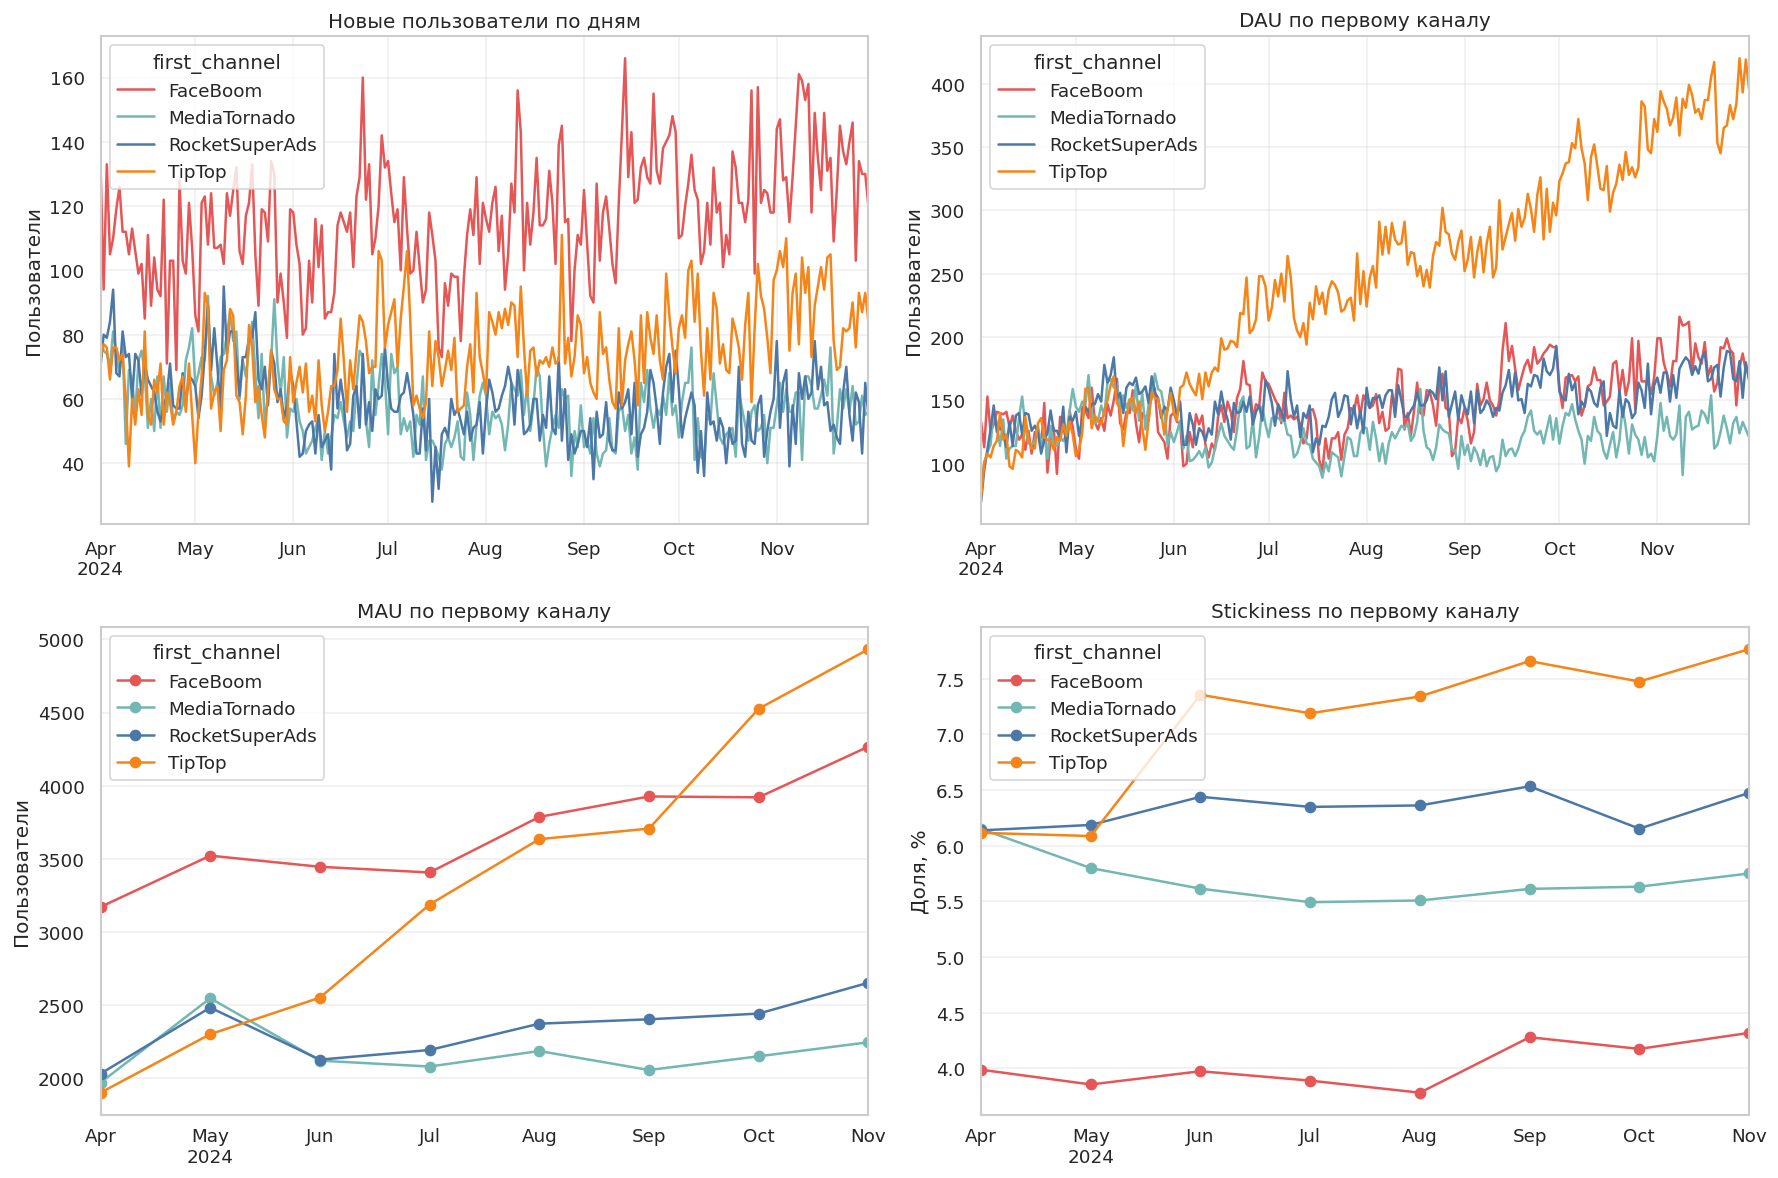

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

channel_daily_users.plot(
    ax=axes[0, 0], color=[CHANNEL_COLORS.get(c) for c in channel_daily_users.columns]
)
axes[0, 0].set_title("Новые пользователи по дням")
axes[0, 0].set_ylabel("Пользователи")
axes[0, 0].set_xlabel("")

channel_dau.pivot(
    index="activity_dt", columns="first_channel", values="dau"
).plot(ax=axes[0, 1], color=[CHANNEL_COLORS.get(c) for c in channels])
axes[0, 1].set_title("DAU по первому каналу")
axes[0, 1].set_ylabel("Пользователи")
axes[0, 1].set_xlabel("")

channel_activity.pivot(
    index="activity_month", columns="first_channel", values="mau"
).plot(
    ax=axes[1, 0], marker="o", color=[CHANNEL_COLORS.get(c) for c in channels]
)
axes[1, 0].set_title("MAU по первому каналу")
axes[1, 0].set_ylabel("Пользователи")
axes[1, 0].set_xlabel("")

channel_activity.pivot(
    index="activity_month",
    columns="first_channel",
    values="stickiness_pct",
).plot(
    ax=axes[1, 1], marker="o", color=[CHANNEL_COLORS.get(c) for c in channels]
)
axes[1, 1].set_title("Stickiness по первому каналу")
axes[1, 1].set_ylabel("Доля, %")
axes[1, 1].set_xlabel("")

for ax in axes.flat:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Вывод.** Рост аудитории во второй половине периода в основном обеспечил TipTop. У этого канала также самый высокий Stickiness — около 7–8%. У FaceBoom он держится около 4%, заметно ниже остальных каналов.

## 7. Недельные когорты и экономика каналов

Для сравнения каналов используются недельные когорты. Rolling retention показывает долю пользователей, вернувшихся хотя бы один раз на 14–28-й день. Покупки и выручка учитываются за лайфтайм 0–27 дней — ровно 28 календарных дней.

In [14]:
weekly_users = (
    profiles.groupby(["cohort_week", "first_channel"], as_index=False)
    .agg(users=("user_id", "nunique"))
)
weekly_costs = (
    costs.assign(
        cohort_week=costs["dt"].dt.to_period("W-SUN").dt.start_time
    )
    .groupby(["cohort_week", "channel"], as_index=False)
    .agg(spend=("costs", "sum"))
    .rename(columns={"channel": "first_channel"})
)
weekly = weekly_users.merge(
    weekly_costs,
    on=["cohort_week", "first_channel"],
    how="left",
    validate="one_to_one",
)

retention_events = visits_cohort.loc[
    visits_cohort["lifetime"].between(
        RETENTION_START_DAY, RETENTION_END_DAY
    )
]
weekly_retained = (
    retention_events.groupby(
        ["cohort_week", "first_channel"], as_index=False
    )
    .agg(retained=("user_id", "nunique"))
)

orders_28 = orders_cohort.loc[
    orders_cohort["lifetime"].between(0, HORIZON_DAYS - 1)
].copy()
weekly_purchases = (
    orders_28.groupby(["cohort_week", "first_channel"], as_index=False)
    .agg(
        buyers=("user_id", "nunique"),
        orders=("user_id", "size"),
        revenue_28d=("revenue", "sum"),
    )
)

weekly = (
    weekly.merge(
        weekly_retained,
        on=["cohort_week", "first_channel"],
        how="left",
        validate="one_to_one",
    )
    .merge(
        weekly_purchases,
        on=["cohort_week", "first_channel"],
        how="left",
        validate="one_to_one",
    )
)
weekly[["retained", "buyers", "orders", "revenue_28d"]] = weekly[
    ["retained", "buyers", "orders", "revenue_28d"]
].fillna(0)

print("Недельных когорт без расходов:", weekly["spend"].isna().sum())

Недельных когорт без расходов: 0


In [15]:
weekly["week_end"] = weekly["cohort_week"] + pd.Timedelta(days=6)
weekly["full_week"] = weekly["week_end"].le(data_end)
weekly["full_financial_window"] = (
    weekly["week_end"] + pd.Timedelta(days=HORIZON_DAYS - 1)
).le(data_end)
weekly["full_retention_window"] = (
    weekly["week_end"] + pd.Timedelta(days=RETENTION_END_DAY)
).le(data_end)

weekly["retention_14_28_pct"] = (
    weekly["retained"] / weekly["users"] * 100
).where(weekly["full_retention_window"])
weekly["conversion_28d_pct"] = (
    weekly["buyers"] / weekly["users"] * 100
).where(weekly["full_financial_window"])
weekly["cac"] = weekly["spend"] / weekly["users"]
weekly["ltv_28d"] = (
    weekly["revenue_28d"] / weekly["users"]
).where(weekly["full_financial_window"])
weekly["roi_28d_pct"] = (
    (weekly["ltv_28d"] - weekly["cac"])
    / weekly["cac"].where(weekly["cac"].ne(0))
    * 100
)

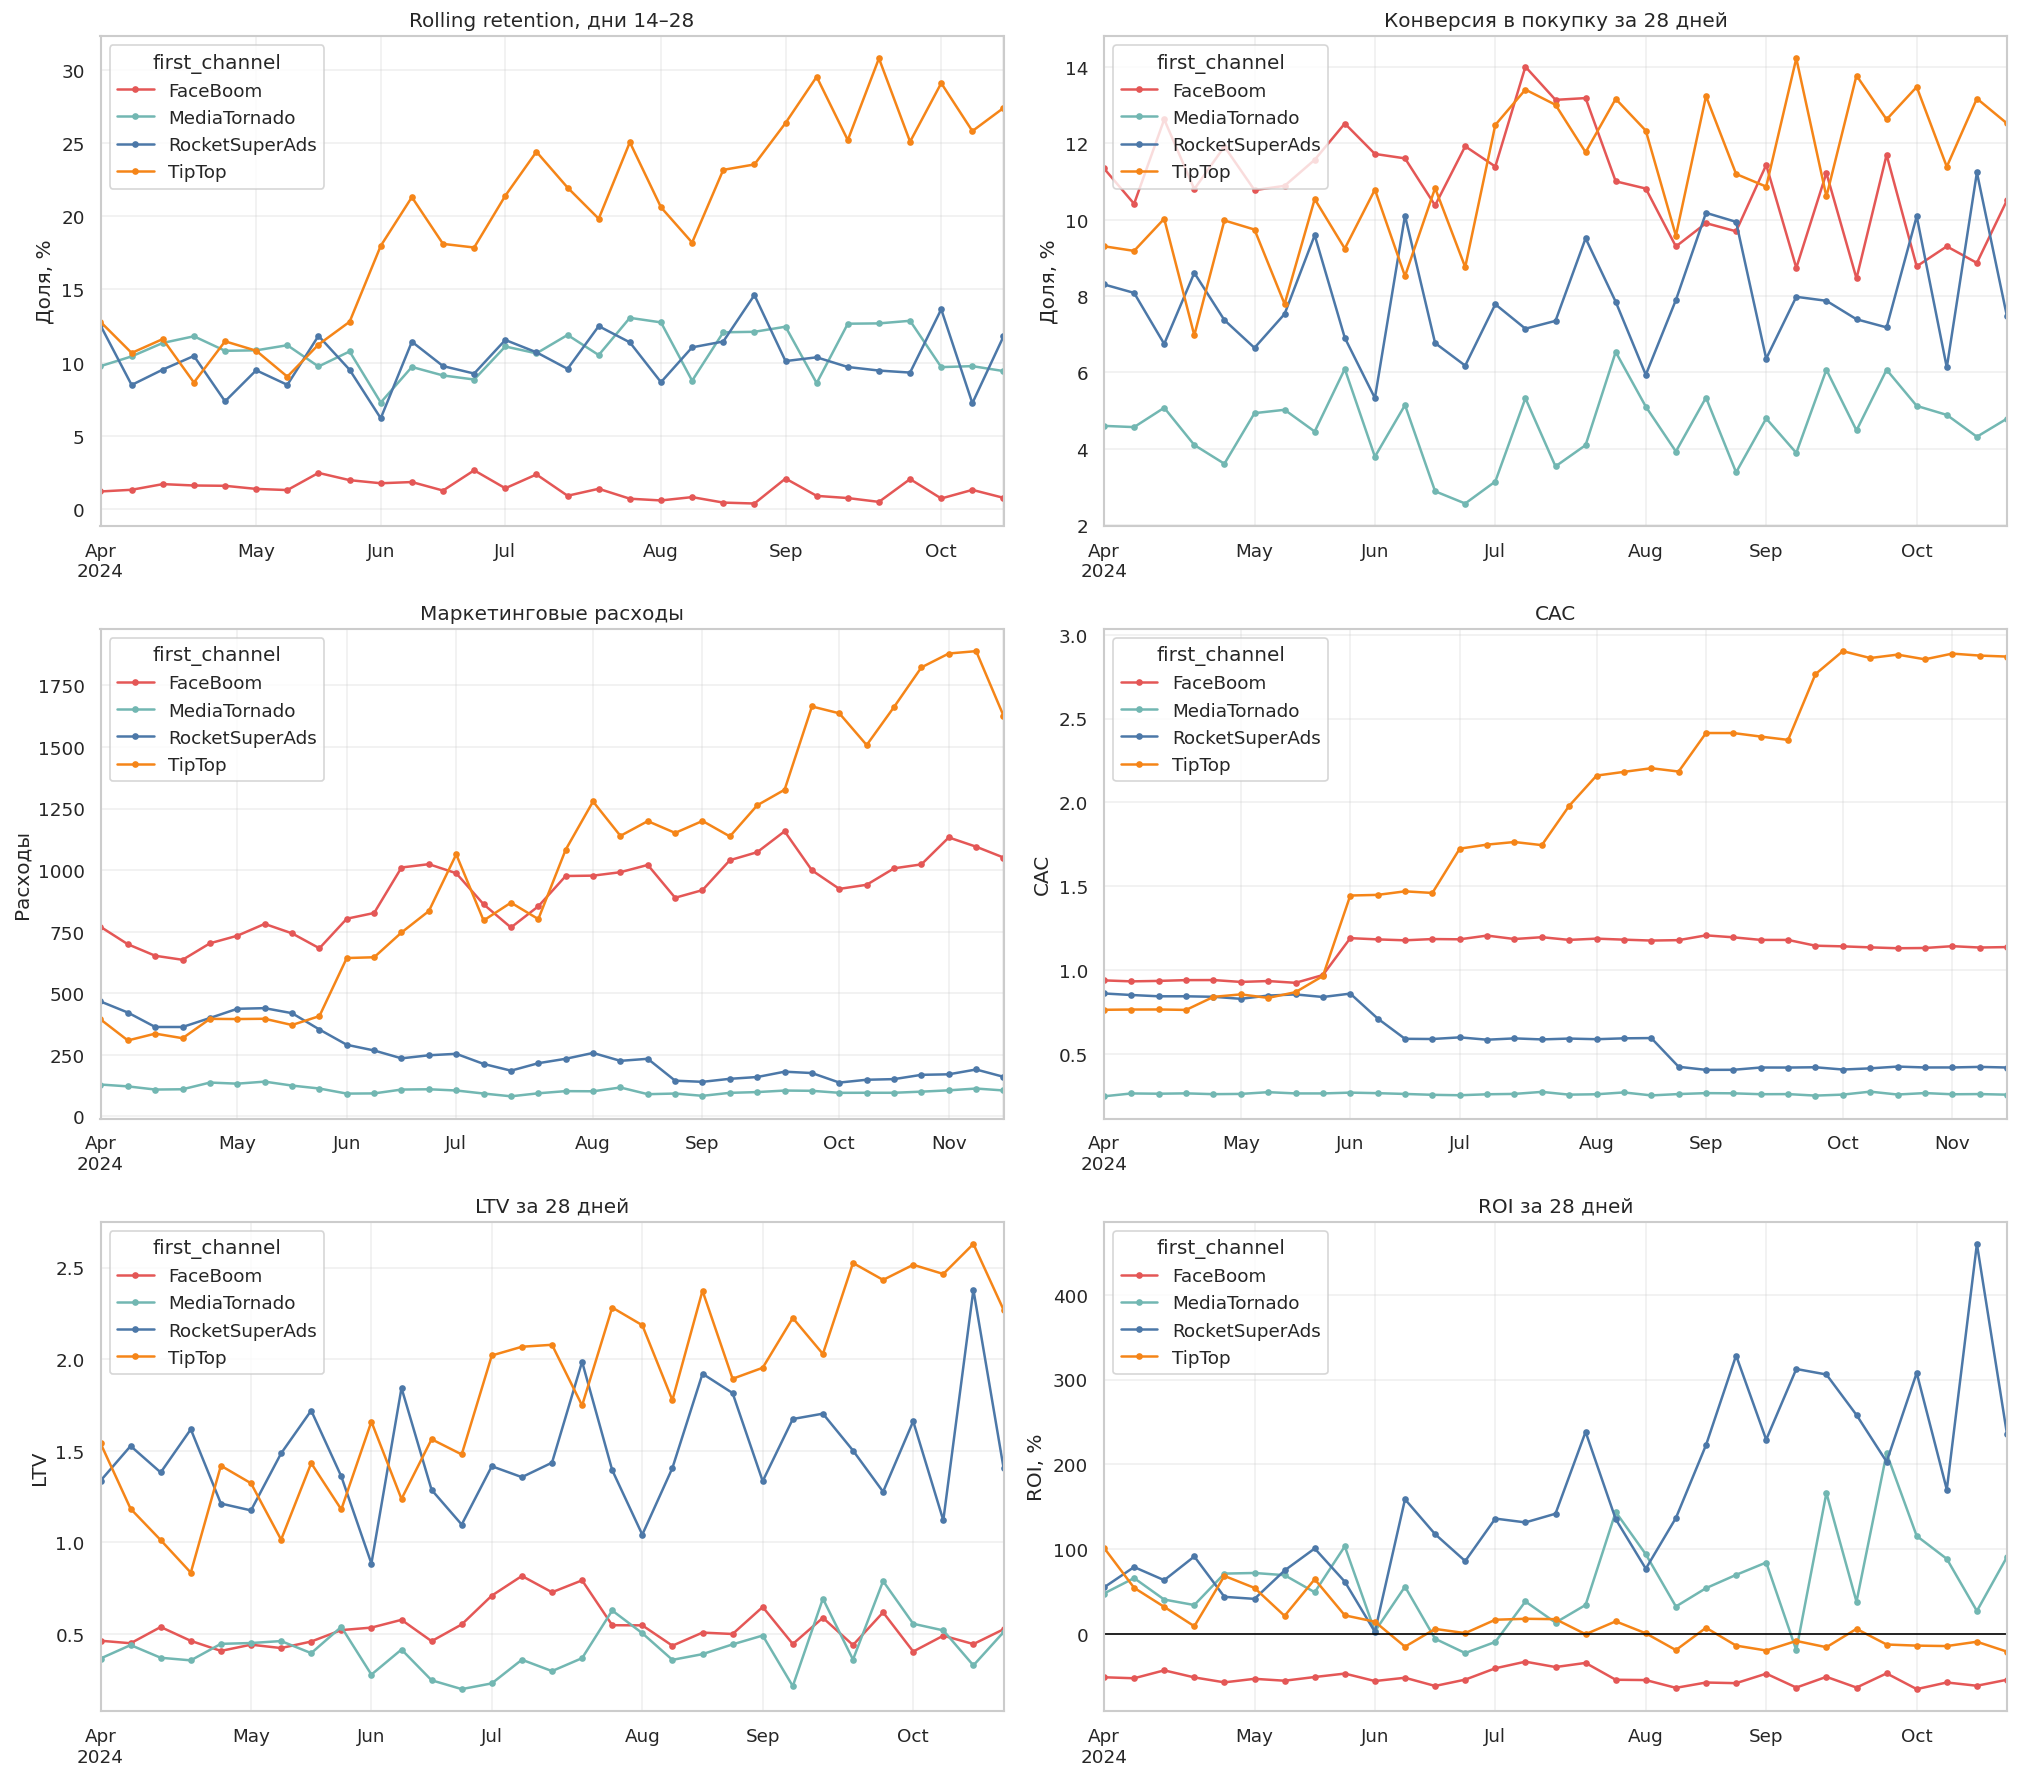

In [16]:
plot_specs = [
    (
        "retention_14_28_pct",
        "Rolling retention, дни 14–28",
        "Доля, %",
        "full_retention_window",
    ),
    (
        "conversion_28d_pct",
        "Конверсия в покупку за 28 дней",
        "Доля, %",
        "full_financial_window",
    ),
    ("spend", "Маркетинговые расходы", "Расходы", "full_week"),
    ("cac", "CAC", "CAC", "full_week"),
    ("ltv_28d", "LTV за 28 дней", "LTV", "full_financial_window"),
    ("roi_28d_pct", "ROI за 28 дней", "ROI, %", "full_financial_window"),
]

fig, axes = plt.subplots(3, 2, figsize=(17, 15))
for ax, (metric, title, ylabel, flag) in zip(axes.flat, plot_specs):
    plot_data = weekly.loc[weekly[flag]]
    pivot = plot_data.pivot(
        index="cohort_week", columns="first_channel", values=metric
    )
    pivot.plot(
        ax=ax,
        marker="o",
        markersize=3,
        color=[CHANNEL_COLORS.get(c) for c in pivot.columns],
    )
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    if metric == "roi_28d_pct":
        ax.axhline(0, color="black", linewidth=1)

plt.tight_layout()
plt.show()

In [17]:
mature_weekly = weekly.loc[weekly["full_retention_window"]]
channel_summary = (
    mature_weekly.groupby("first_channel", as_index=False)
    .agg(
        users=("users", "sum"),
        spend=("spend", "sum"),
        revenue_28d=("revenue_28d", "sum"),
        retained=("retained", "sum"),
        buyers=("buyers", "sum"),
        orders=("orders", "sum"),
    )
)
channel_summary["cac"] = channel_summary["spend"] / channel_summary["users"]
channel_summary["ltv_28d"] = (
    channel_summary["revenue_28d"] / channel_summary["users"]
)
channel_summary["roi_28d_pct"] = (
    (channel_summary["revenue_28d"] - channel_summary["spend"])
    / channel_summary["spend"]
    * 100
)
channel_summary["retention_14_28_pct"] = (
    channel_summary["retained"] / channel_summary["users"] * 100
)
channel_summary["conversion_28d_pct"] = (
    channel_summary["buyers"] / channel_summary["users"] * 100
)
channel_summary["arppu_28d"] = (
    channel_summary["revenue_28d"] / channel_summary["buyers"]
)
channel_summary["orders_per_buyer"] = (
    channel_summary["orders"] / channel_summary["buyers"]
)
channel_summary["avg_order_value"] = (
    channel_summary["revenue_28d"] / channel_summary["orders"]
)

summary_columns = [
    "first_channel",
    "users",
    "cac",
    "ltv_28d",
    "roi_28d_pct",
    "retention_14_28_pct",
    "conversion_28d_pct",
    "arppu_28d",
    "orders_per_buyer",
    "avg_order_value",
]
display(
    channel_summary[summary_columns]
    .sort_values("roi_28d_pct", ascending=False)
    .round(2)
)

,first_channel,users,cac,ltv_28d,roi_28d_pct,retention_14_28_pct,conversion_28d_pct,arppu_28d,orders_per_buyer,avg_order_value
2,RocketSuperAds,12284,0.64,1.47,127.89,10.21,7.84,18.73,5.44,3.44
1,MediaTornado,12114,0.26,0.42,59.47,10.75,4.56,9.17,2.65,3.47
3,TipTop,15081,1.79,1.85,3.21,20.18,11.18,16.51,4.79,3.44
0,FaceBoom,23854,1.11,0.53,-52.33,1.33,10.89,4.85,1.40,3.47


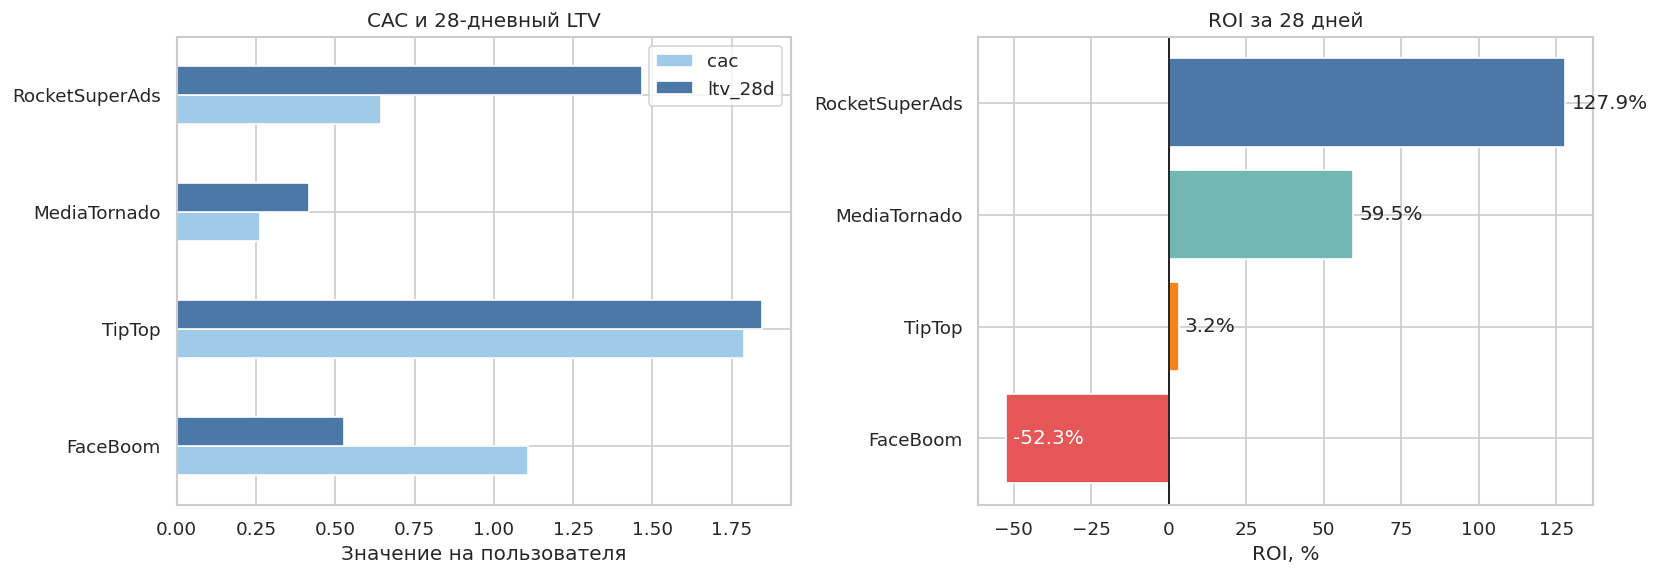

In [18]:
channel_order = (
    channel_summary.sort_values("roi_28d_pct")["first_channel"].tolist()
)
plot_summary = channel_summary.set_index("first_channel").loc[channel_order]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_summary[["cac", "ltv_28d"]].plot(
    kind="barh", ax=axes[0], color=["#A0CBE8", "#4C78A8"]
)
axes[0].set_title("CAC и 28-дневный LTV")
axes[0].set_xlabel("Значение на пользователя")
axes[0].set_ylabel("")

roi_bars = axes[1].barh(
    plot_summary.index,
    plot_summary["roi_28d_pct"],
    color=[CHANNEL_COLORS.get(c) for c in plot_summary.index],
)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("ROI за 28 дней")
axes[1].set_xlabel("ROI, %")
for bar, value in zip(roi_bars, plot_summary["roi_28d_pct"]):
    if value < 0:
        axes[1].text(
            value + 2,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.1f}%",
            va="center",
            ha="left",
            color="white",
        )
    else:
        axes[1].text(
            value + 2,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.1f}%",
            va="center",
            ha="left",
        )

plt.tight_layout()
plt.show()

**Вывод.** RocketSuperAds показывает лучший 28-дневный ROI: +127,9% при CAC 0,64 и LTV 1,47. MediaTornado также окупается (+59,5%) благодаря низкому CAC 0,26. TipTop имеет высокие удержание и LTV, но его ROI составляет только +3,2% из-за CAC 1,79. FaceBoom не окупается: ROI −52,3%, CAC 1,11 против LTV 0,53.

## 8. Почему FaceBoom не окупается

Высокая конверсия FaceBoom не превращается в высокий LTV. Разложим выручку платящего пользователя на средний чек и число покупок.

,first_channel,conversion_28d_pct,arppu_28d,orders_per_buyer,avg_order_value,retention_14_28_pct
2,RocketSuperAds,7.84,18.73,5.44,3.44,10.21
3,TipTop,11.18,16.51,4.79,3.44,20.18
1,MediaTornado,4.56,9.17,2.65,3.47,10.75
0,FaceBoom,10.89,4.85,1.40,3.47,1.33


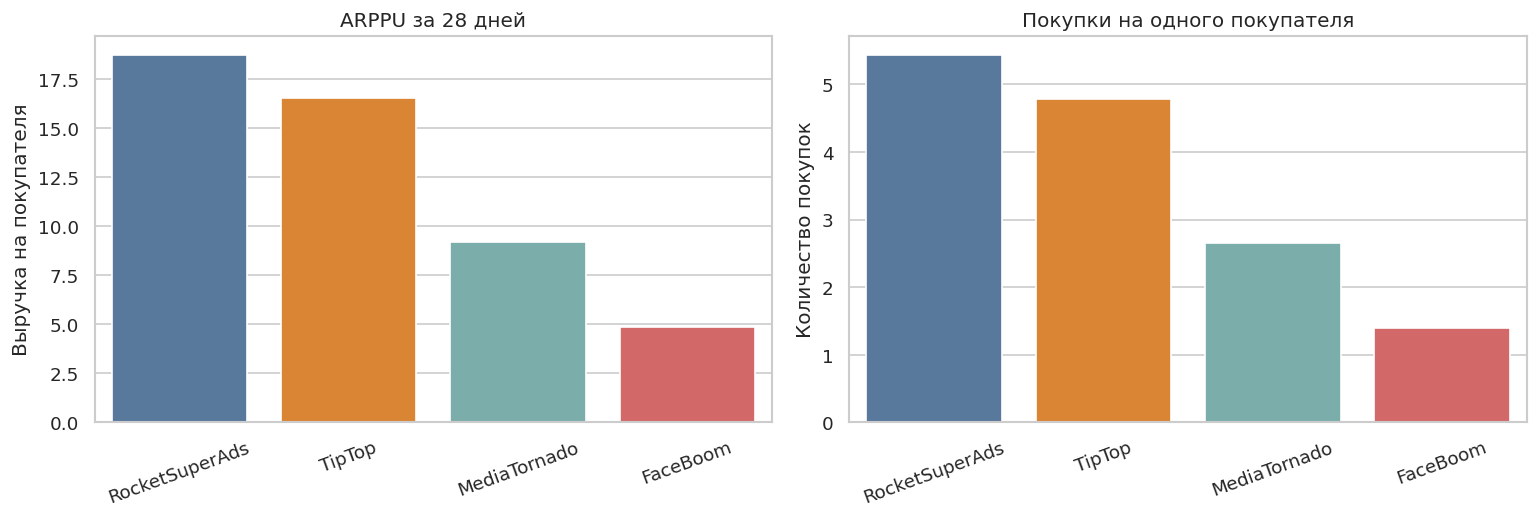

In [19]:
monetization = (
    channel_summary[
        [
            "first_channel",
            "conversion_28d_pct",
            "arppu_28d",
            "orders_per_buyer",
            "avg_order_value",
            "retention_14_28_pct",
        ]
    ]
    .sort_values("arppu_28d", ascending=False)
    .round(2)
)
display(monetization)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(
    data=monetization,
    x="first_channel",
    y="arppu_28d",
    hue="first_channel",
    legend=False,
    palette=CHANNEL_COLORS,
    ax=axes[0],
)
axes[0].set_title("ARPPU за 28 дней")
axes[0].set_xlabel("")
axes[0].set_ylabel("Выручка на покупателя")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    data=monetization,
    x="first_channel",
    y="orders_per_buyer",
    hue="first_channel",
    legend=False,
    palette=CHANNEL_COLORS,
    ax=axes[1],
)
axes[1].set_title("Покупки на одного покупателя")
axes[1].set_xlabel("")
axes[1].set_ylabel("Количество покупок")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

**Диагноз.** Средний чек практически одинаков во всех каналах — около 3,45. Проблема FaceBoom не в размере разовой покупки, а в повторных покупках: 1,40 покупки на платящего пользователя против 2,65–5,44 у остальных каналов. Поэтому ARPPU FaceBoom составляет лишь 4,85, а rolling retention — 1,33%. Канал приводит много разовых покупателей, которые почти не возвращаются.

## 9. Срок окупаемости убыточного канала

Для канала с отрицательным ROI рассчитаем накопленную выручку и ROI на горизонте десяти недель. Для итоговой кривой используется один и тот же набор когорт, полностью проживших все десять недель.

In [20]:
loss_channels = channel_summary.loc[
    channel_summary["roi_28d_pct"].lt(0), "first_channel"
].tolist()
print("Каналы без окупаемости за 28 дней:", loss_channels)

orders_10_weeks = orders_cohort.loc[
    orders_cohort["first_channel"].isin(loss_channels)
    & orders_cohort["lifetime"].between(0, 69)
].copy()
orders_10_weeks["age_week"] = orders_10_weeks["lifetime"] // 7

revenue_by_week = (
    orders_10_weeks.groupby(
        ["cohort_week", "first_channel", "age_week"], as_index=False
    )
    .agg(week_revenue=("revenue", "sum"))
)

roi_by_age = (
    weekly.loc[
        weekly["first_channel"].isin(loss_channels) & weekly["full_week"],
        ["cohort_week", "first_channel", "spend"],
    ]
    .merge(pd.DataFrame({"age_week": range(10)}), how="cross")
    .merge(
        revenue_by_week,
        on=["cohort_week", "first_channel", "age_week"],
        how="left",
        validate="one_to_one",
    )
    .sort_values(["first_channel", "cohort_week", "age_week"])
)
roi_by_age["week_revenue"] = roi_by_age["week_revenue"].fillna(0)
roi_by_age["cumulative_revenue"] = roi_by_age.groupby(
    ["first_channel", "cohort_week"]
)["week_revenue"].cumsum()

last_required_day = 6 + 7 * (roi_by_age["age_week"] + 1) - 1
roi_by_age["complete_window"] = (
    roi_by_age["cohort_week"]
    + pd.to_timedelta(last_required_day, unit="D")
).le(data_end)
roi_by_age["roi_pct"] = (
    (roi_by_age["cumulative_revenue"] - roi_by_age["spend"])
    / roi_by_age["spend"]
    * 100
).where(roi_by_age["complete_window"])

Каналы без окупаемости за 28 дней: ['FaceBoom']


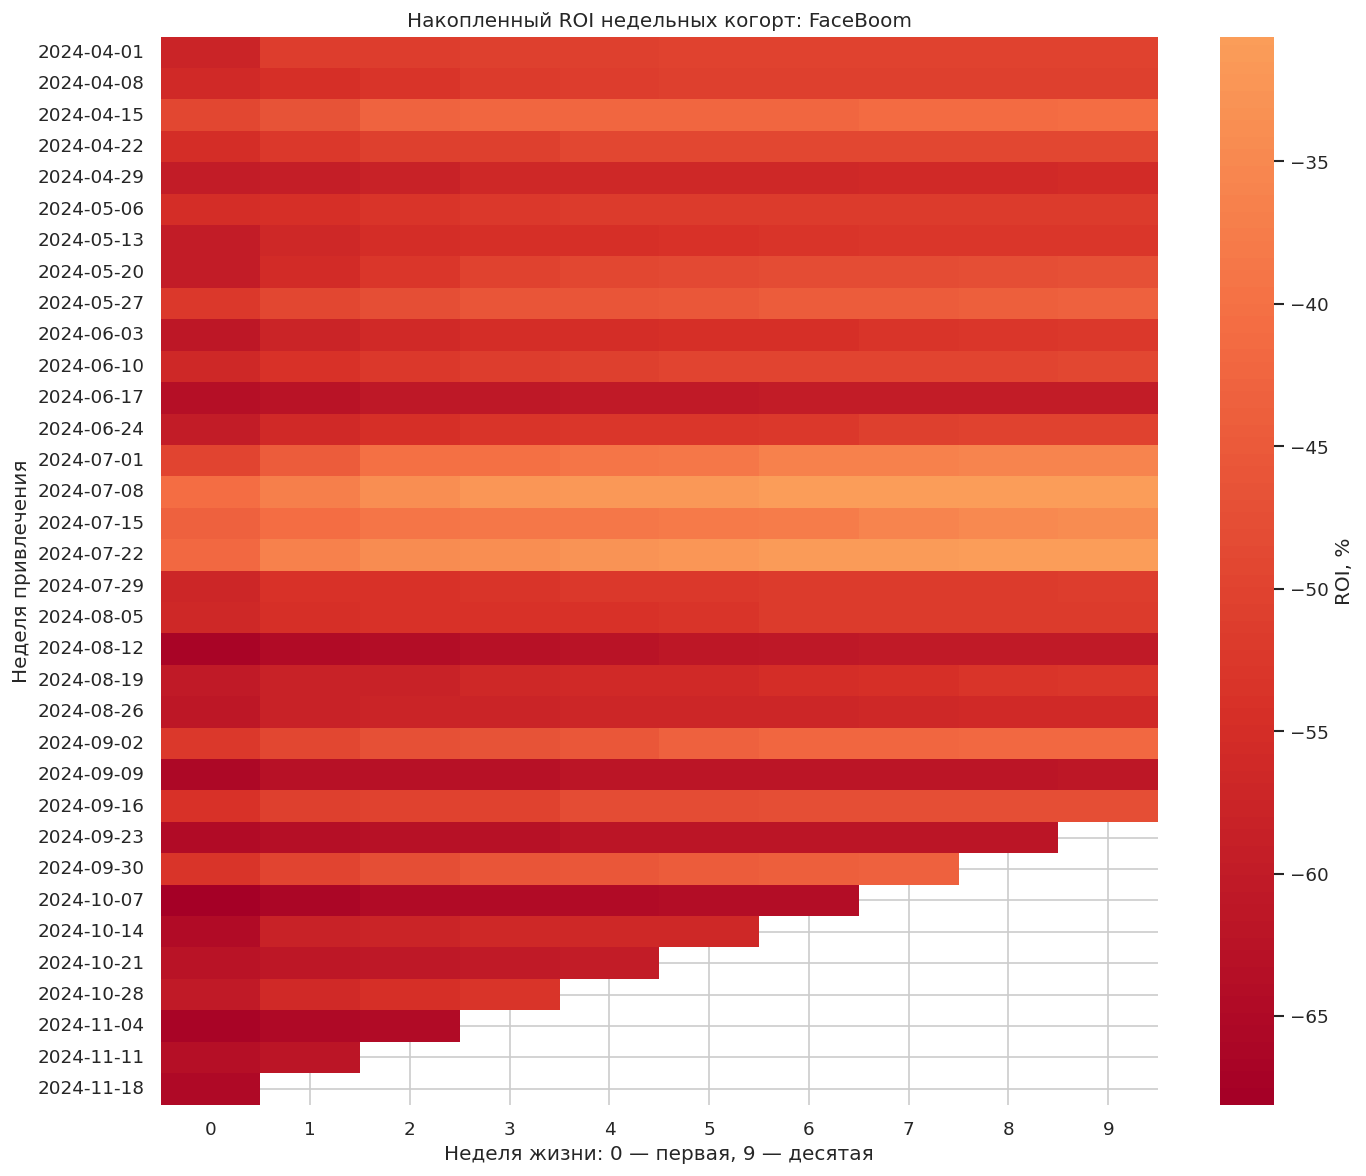

In [21]:
for channel in loss_channels:
    heatmap_data = roi_by_age.loc[
        roi_by_age["first_channel"].eq(channel)
    ].pivot(index="cohort_week", columns="age_week", values="roi_pct")
    heatmap_data.index = heatmap_data.index.strftime("%Y-%m-%d")

    plt.figure(figsize=(12, 10))
    sns.heatmap(
        heatmap_data,
        cmap="RdYlGn",
        center=0,
        mask=heatmap_data.isna(),
        cbar_kws={"label": "ROI, %"},
    )
    plt.title(f"Накопленный ROI недельных когорт: {channel}")
    plt.xlabel("Неделя жизни: 0 — первая, 9 — десятая")
    plt.ylabel("Неделя привлечения")
    plt.tight_layout()
    plt.show()

,first_channel,age_week,cohorts,cumulative_revenue,spend,week_number,roi_pct
7,FaceBoom,7,25,10890.90,21418.15,8,-49.15
8,FaceBoom,8,25,10952.22,21418.15,9,-48.86
9,FaceBoom,9,25,10994.09,21418.15,10,-48.67


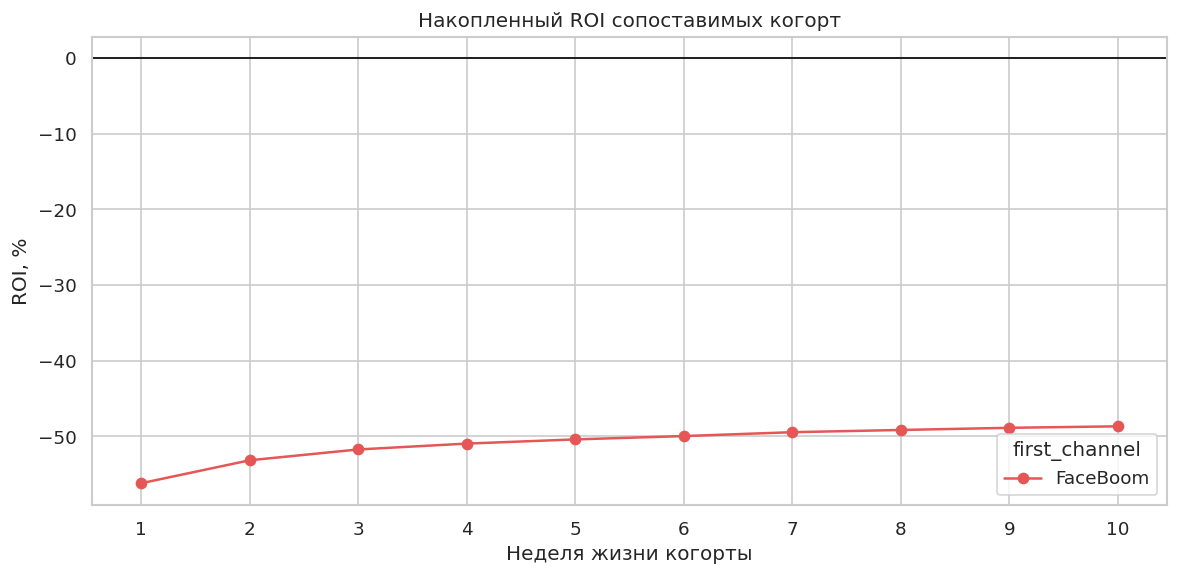

In [22]:
complete_10_week_cohorts = roi_by_age.loc[
    roi_by_age["age_week"].eq(9) & roi_by_age["complete_window"],
    ["cohort_week", "first_channel"],
]
comparable_cohorts = roi_by_age.merge(
    complete_10_week_cohorts,
    on=["cohort_week", "first_channel"],
    how="inner",
    validate="many_to_one",
)
payback_curve = (
    comparable_cohorts.groupby(
        ["first_channel", "age_week"], as_index=False
    )
    .agg(
        cohorts=("cohort_week", "nunique"),
        cumulative_revenue=("cumulative_revenue", "sum"),
        spend=("spend", "sum"),
    )
)
payback_curve["week_number"] = payback_curve["age_week"] + 1
payback_curve["roi_pct"] = (
    (payback_curve["cumulative_revenue"] - payback_curve["spend"])
    / payback_curve["spend"]
    * 100
)

ax = payback_curve.pivot(
    index="week_number", columns="first_channel", values="roi_pct"
).plot(
    marker="o",
    figsize=(10, 5),
    color=[CHANNEL_COLORS.get(c) for c in loss_channels],
)
ax.axhline(0, color="black", linewidth=1)
ax.set_title("Накопленный ROI сопоставимых когорт")
ax.set_xlabel("Неделя жизни когорты")
ax.set_ylabel("ROI, %")
ax.set_xticks(range(1, 11))
plt.tight_layout()
plt.show()

display(payback_curve.tail(3).round(2))

**Вывод.** Для 25 недельных когорт FaceBoom, полностью проживших десять недель, ROI остаётся отрицательным на всём горизонте и составляет −48,7% к концу десятой недели. После четвёртой недели улучшение минимально, поэтому проблема не решается простым увеличением срока ожидания.

## 10. Бюджет и общая динамика выручки

,channel,spend,share_pct
3,TipTop,35676.61,44.75
0,FaceBoom,31621.37,39.66
2,RocketSuperAds,8744.38,10.97
1,MediaTornado,3688.94,4.63


,month,revenue,buyers,mau,revenue_per_mau
0,2024-04-01,5847.16,757,9069,0.64
1,2024-05-01,9253.21,1167,10849,0.85
2,2024-06-01,10493.20,1397,10240,1.02
3,2024-07-01,14001.20,1774,10864,1.29
4,2024-08-01,16372.39,2060,11977,1.37
5,2024-09-01,17568.24,2276,12089,1.45
6,2024-10-01,20596.58,2610,13036,1.58
7,2024-11-01,22458.09,2865,14097,1.59


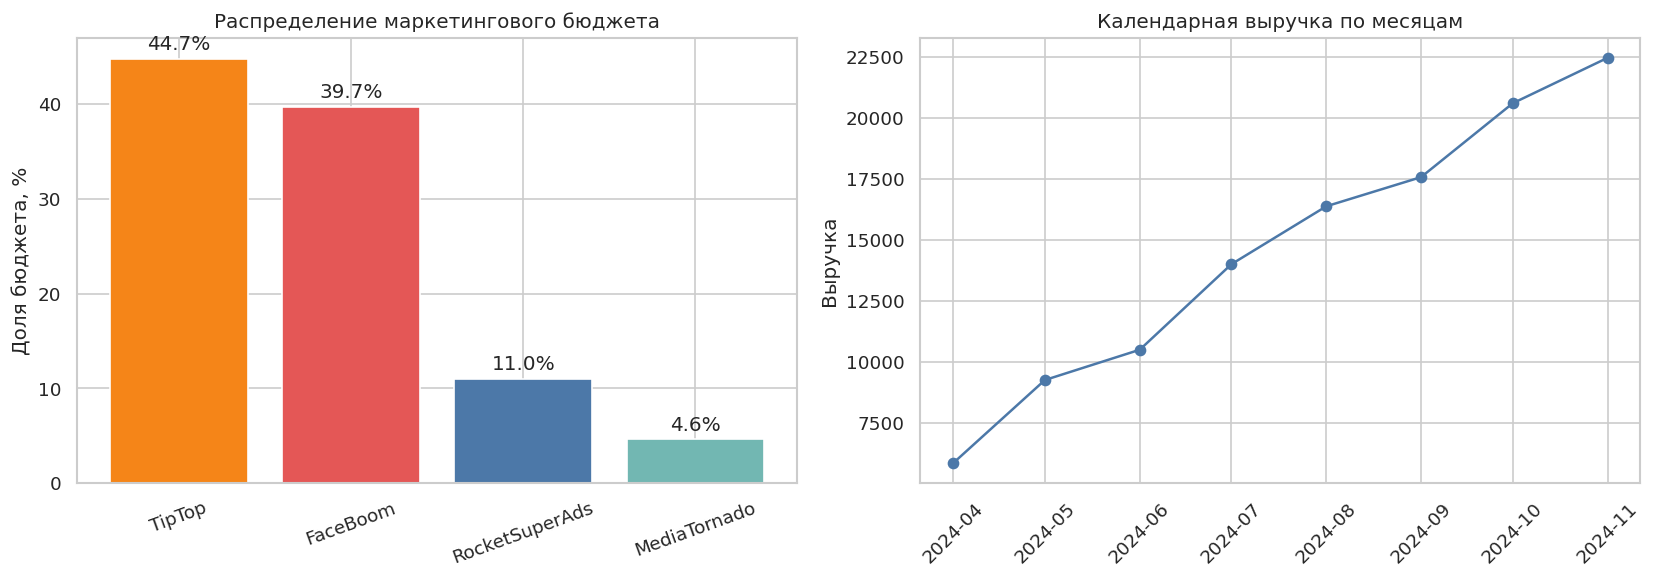

In [23]:
spend_share = (
    costs.groupby("channel", as_index=False)
    .agg(spend=("costs", "sum"))
    .sort_values("spend", ascending=False)
)
spend_share["share_pct"] = (
    spend_share["spend"] / spend_share["spend"].sum() * 100
)

calendar_revenue = (
    orders.assign(
        month=orders["event_dt"].dt.to_period("M").dt.to_timestamp()
    )
    .groupby("month", as_index=False)
    .agg(revenue=("revenue", "sum"), buyers=("user_id", "nunique"))
    .merge(
        monthly_activity[["activity_month", "mau"]].rename(
            columns={"activity_month": "month"}
        ),
        on="month",
        validate="one_to_one",
    )
)
calendar_revenue["revenue_per_mau"] = (
    calendar_revenue["revenue"] / calendar_revenue["mau"]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
spend_bars = axes[0].bar(
    spend_share["channel"],
    spend_share["share_pct"],
    color=[CHANNEL_COLORS[channel] for channel in spend_share["channel"]],
)
axes[0].set_title("Распределение маркетингового бюджета")
axes[0].set_xlabel("")
axes[0].set_ylabel("Доля бюджета, %")
axes[0].tick_params(axis="x", rotation=20)
axes[0].bar_label(spend_bars, fmt="%.1f%%", padding=3)

axes[1].plot(
    calendar_revenue["month"],
    calendar_revenue["revenue"],
    marker="o",
    color="#4C78A8",
)
axes[1].set_title("Календарная выручка по месяцам")
axes[1].set_xlabel("")
axes[1].set_ylabel("Выручка")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

display(spend_share.round(2))
display(calendar_revenue.round(2))

## 11. Выводы и рекомендации

### Основные результаты

- MAU вырос с 9 069 до 14 097, календарная выручка — с 5 847 до 22 458.
- CAC растёт быстрее LTV: с апреля по октябрь 28-дневный ROI снизился с +11,4% до −9,1%.
- 84,4% бюджета сосредоточено в TipTop и FaceBoom.
- RocketSuperAds имеет лучший ROI (+127,9%), MediaTornado — +59,5%.
- TipTop почти на границе окупаемости (+3,2%) из-за высокого CAC.
- FaceBoom получает 39,7% бюджета, но теряет 52,3% маркетинговых вложений за 28 дней и не окупается даже за десять недель.
- Причина слабого LTV FaceBoom — не средний чек, а низкая повторяемость покупок и минимальное удержание.

### Рекомендации маркетингу

1. **Сократить масштабные закупки в FaceBoom.** Оставить ограниченные тесты новых аудиторий, креативов и onboarding-сценариев.
2. **Перераспределить часть бюджета в RocketSuperAds и MediaTornado**, но наращивать расходы поэтапно: текущая эффективность доказана на меньшем объёме бюджета.
3. **Не масштабировать TipTop без контроля CAC.** Канал качественный по удержанию и повторным покупкам, но запас окупаемости составляет всего около 3%.
4. **Для FaceBoom работать с повторными покупками:** персональные рекомендации, цепочки возврата, пакетные предложения и тесты контента после первой покупки.
5. **Контролировать метрики по зрелым когортам.** Неполные когорты нельзя сравнивать с пользователями, прожившими весь горизонт.

### Ограничения

- ROI учитывает только маркетинговые расходы; себестоимость контента и другие операционные затраты отсутствуют.
- Данные не позволяют установить причинный эффект запуска спортивного контента: нет информации о выбранных пакетах или экспериментальной группы.
- Выводы относятся к наблюдаемому периоду и могут измениться при масштабировании эффективных каналов.